# DSC 411/511 Project
# Notebook 08: RQ6 (new): Do Lower-Income Neighbourhoods Get Paid Less, After We Account for the Flood?

**Class topics:** Lecture 07 (logistic regression and reading coefficients, odds), Lecture 03 (discretization into
quintiles, aggregation), Lecture 04 (confounding features), plus regression with controls as an extension.

---

**How this question was derived.** In notebook 02 the ACS columns (income, % owners, % non-Hispanic White) had high
mutual information with both outcomes. That can mean two very different things:
1. **Exposure**: poorer and richer neighbourhoods sit in different places, and floods hit places unequally; or
2. **Treatment**: similar claims are settled differently depending on the neighbourhood.

Published work points to (2), at least in part:
- The **Urban Institute** study *Housing Resilience in Greater New Orleans* (2008-2018) found **no differences by
  race/ethnicity or income in the cost and coverage of equivalent policies**, but did find **"apparent differences in
  claims treatment"**.
- *Are Underserved Populations Left Out of National Flood Mitigation Efforts...?* (J. Climate Resilience and Justice,
  2023) found that majority non-White tracts in majority-White counties receive **disproportionately fewer NFIP
  claims** per person.

Both are descriptive: they do not control for how hard each claim was hit. The combined dataset lets us repeat the raw
comparison and then add controls for building, policy, storm and damage.

> **RQ6. Do claims in lower-income (and majority non-White) neighbourhoods have higher non-payment rates and lower
> payment-to-damage ratios, and does the gap remain after controlling for building, policy, storm exposure and damage?**

**Caution (ecological inference).** ACS values describe the **block group**, not the policyholder. We can talk about
neighbourhoods, not about individual households.

---
# Section 0: Setup

In [1]:
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 180)

claims = load_clean_claims()
claims = claims[claims['acs_join_level'] != 'none'].copy()
print(f'Claims with an ACS match: {len(claims):,}')

Claims with an ACS match: 251,637


---
# Section 1: Building the Neighbourhood Groups (discretization, Lecture 03)

Income is split into **quintiles** using the claim population, so each group has about 20% of claims.
Race is a simple, published-style split: majority non-Hispanic White (> 50%) or not.

In [2]:
claims['income_quintile'] = pd.qcut(claims['acs_median_household_income'], 5, labels=['Q1_lowest', 'Q2', 'Q3', 'Q4', 'Q5_highest'])
claims['majority_white'] = np.where(claims['acs_pct_non_hispanic_white'] > 50, 'majority_NH_white', 'majority_non_white')
quintile_edges = claims.groupby('income_quintile')['acs_median_household_income'].agg(['min', 'max']).round(0)
print('Income quintile edges (block-group median household income, $):')
print(quintile_edges.to_string())
print('\nClaims by race group:', claims['majority_white'].value_counts().to_dict())

# Payment-to-damage ratio: only where there was damage. Clipped at 1.5 because payments can include items not in
# buildingDamageAmount (notebook 01, Section 5.2).
damaged = claims[claims['buildingDamageAmount'] > 0].copy()
damaged['payment_to_damage_ratio'] = (damaged['amountPaidOnBuildingClaim'] / damaged['buildingDamageAmount']).clip(0, 1.5)
claims['not_paid'] = 1 - claims['building_paid_flag']

Income quintile edges (block-group median household income, $):
                      min       max
income_quintile                    
Q1_lowest          2499.0   58065.0
Q2                58068.0   73917.0
Q3                73920.0   92262.0
Q4                92264.0  124125.0
Q5_highest       124127.0  250001.0

Claims by race group: {'majority_NH_white': 202816, 'majority_non_white': 48821}


---
# Section 2: Reproducing the Raw (Unadjusted) Comparison

In [3]:
raw_by_income = claims.groupby('income_quintile').agg(claims=('id', 'size'), not_paid_rate=('not_paid', 'mean'),
                                                      median_paid_if_paid=('amountPaidOnBuildingClaim', lambda s: s[s > 0].median()),
                                                      median_damage=('buildingDamageAmount', 'median'),
                                                      median_rain_3day=('rain_3day_mm', 'median'),
                                                      share_inside_SFHA=('in_special_flood_hazard_area', 'mean'),
                                                      median_coverage=('totalBuildingInsuranceCoverage', 'median'))
raw_by_income['median_payment_to_damage'] = damaged.groupby('income_quintile')['payment_to_damage_ratio'].median()
raw_by_race = claims.groupby('majority_white').agg(claims=('id', 'size'), not_paid_rate=('not_paid', 'mean'),
                                                   median_paid_if_paid=('amountPaidOnBuildingClaim', lambda s: s[s > 0].median()),
                                                   median_damage=('buildingDamageAmount', 'median'),
                                                   median_rain_3day=('rain_3day_mm', 'median'),
                                                   share_inside_SFHA=('in_special_flood_hazard_area', 'mean'),
                                                   median_coverage=('totalBuildingInsuranceCoverage', 'median'))
raw_by_race['median_payment_to_damage'] = damaged.groupby('majority_white')['payment_to_damage_ratio'].median()
print('By income quintile:')
print(raw_by_income.round(3).to_string())
print('\nBy race group:')
print(raw_by_race.round(3).to_string())
raw_by_income.round(4).to_csv(TABLE_DIR / '08_rq6_raw_by_income.csv')
raw_by_race.round(4).to_csv(TABLE_DIR / '08_rq6_raw_by_race.csv')

By income quintile:
                 claims  not_paid_rate  median_paid_if_paid  median_damage  median_rain_3day  share_inside_SFHA  median_coverage  median_payment_to_damage
income_quintile                                                                                                                                           
Q1_lowest         50330          0.176            34143.720        26461.0           133.900              0.757         200000.0                     0.940
Q2                50368          0.178            40815.410        29468.0           142.636              0.819         250000.0                     0.945
Q3                50297          0.167            47820.660        33494.0           138.362              0.831         250000.0                     0.953
Q4                50568          0.169            43129.755        31542.5           105.290              0.836         250000.0                     0.950
Q5_highest        50074          0.147            

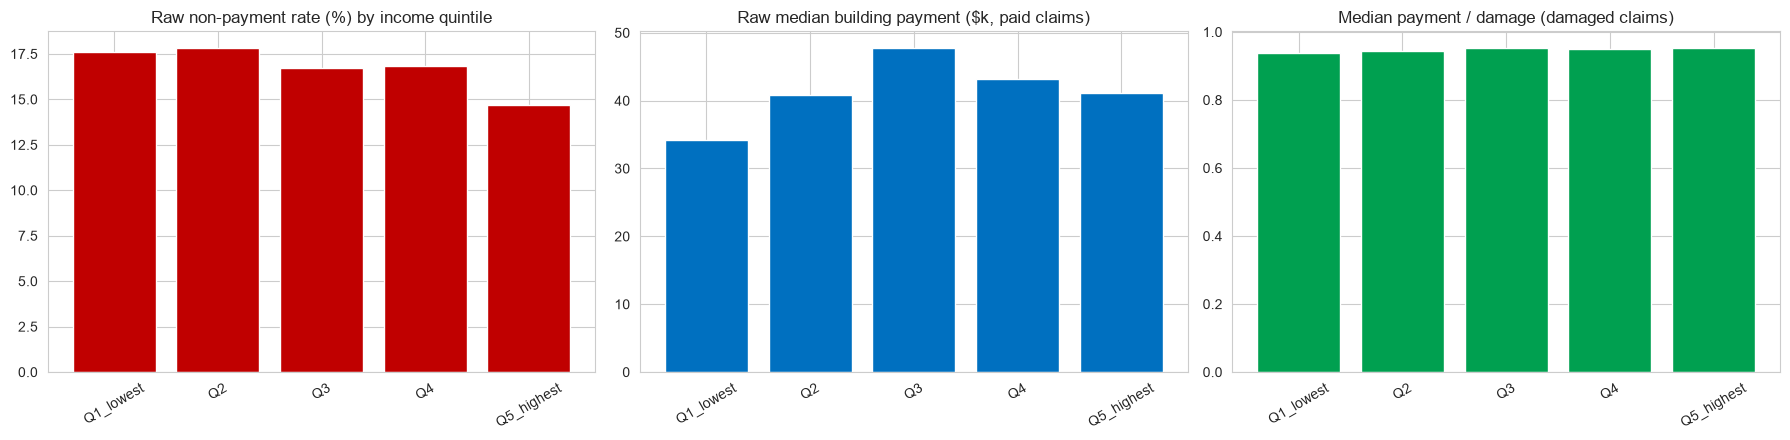

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].bar(raw_by_income.index.astype(str), raw_by_income['not_paid_rate'] * 100, color='#C00000')
axes[0].set_title('Raw non-payment rate (%) by income quintile')
axes[1].bar(raw_by_income.index.astype(str), raw_by_income['median_paid_if_paid'] / 1000, color='#0070C0')
axes[1].set_title('Raw median building payment ($k, paid claims)')
axes[2].bar(raw_by_income.index.astype(str), raw_by_income['median_payment_to_damage'], color='#00A050')
axes[2].set_title('Median payment / damage (damaged claims)')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '08_raw_by_income.png', dpi=120)
plt.show()

**Reading the raw numbers.**
- **Income.** Claims in the lowest-income quintile (block-group income below about $58k) were not paid 17.6% of the
  time, against 14.7% in the highest quintile. Their median payment was $34k against $41k.
- **Race.** Claims in majority non-White block groups were not paid 21.0% of the time, against 15.7%. Their median
  payment was $30k against $44k.
- **But the groups were not hit in the same way.** Majority non-White areas had much more rain (median 3-day rain
  176 mm vs 111 mm), fewer claims inside the SFHA (67% vs 85%) and lower damage ($22k vs $33k). The lowest
  income quintile has lower coverage ($200k vs $250k) and fewer SFHA claims. Lower payments partly follow lower
  damage and lower coverage. A raw gap mixes treatment with exposure, so we need controls.

---
# Section 3: Logistic Regression with Controls (Lecture 07, Sections 1-2)

For non-payment we fit four nested logistic models. Each adds one block of controls. The coefficient of each income
quintile, turned into an **odds ratio** (OR = e^coefficient), compares that quintile with the **highest** quintile.
OR = 1 means no difference; OR > 1 means higher odds of not being paid.

| Model | Controls |
|---|---|
| M1 | none (raw gap) |
| M2 | + building and policy: flood zone, occupancy, foundation, coverage, deductible, age, primary residence, RR2.0 |
| M3 | + flood exposure: PRISM rain, storm distance and wind, coast distance, **state and loss year** |
| M4 | + **adjuster damage** (log). **Sensitivity check only** (see below) |

**Why M3 is the main result and M4 only a sensitivity check.** M4 asks "are claims with the *same damage* paid
differently?". That sounds like the right fairness question, but the adjuster's damage is a problem as a control:

1. **Payment is almost a formula of damage.** Payment = damage minus deductible, capped by coverage. A claim with
   damage below the deductible is "not paid" by definition. So controlling for damage removes much of the variation
   we want to explain.
2. **Damage is measured after the flood, by the same claim process we are testing (a "bad control").** If damage
   is assessed or documented differently in lower-income neighbourhoods (for example, fewer receipts or a quicker
   inspection), then part of any unequal treatment is already *inside* the damage number. Controlling for it hides
   that part of the gap. In causal language, damage is a post-treatment variable (a mediator).

M3 controls for everything known **before** the claim process (building, policy, flood exposure, state, year), so it
is our main estimate. M4 shows how much of the M3 gap is "explained" by the recorded damage; it is a lower bound,
not the answer.

Standard errors are **clustered by county**, because claims in the same county share a storm and a local adjusting
team, so they are not independent.

In [5]:
claims['log_coverage'] = claims['log_building_coverage']
claims['log_deductible'] = np.log10(claims['building_deductible_usd'])
claims['log_rain_3day'] = np.log1p(claims['rain_3day_mm'])
claims['log_storm_distance'] = np.log1p(claims['storm_distance_km'])
claims['log_coast_distance'] = np.log1p(claims['coast_distance_km'])
claims['log_damage'] = np.log1p(claims['buildingDamageAmount'])
claims['loss_year_text'] = claims['loss_year'].astype(str)

BUILDING_POLICY = ('C(flood_zone_group) + C(occupancy_group) + C(foundation_group) + log_coverage + log_deductible'
                   ' + building_age_at_loss + primaryResidenceIndicator + rated_by_risk_rating_2')
EXPOSURE = 'log_rain_3day + log_storm_distance + storm_wind_proxy_at_claim_kt + log_coast_distance + C(state) + C(loss_year_text)'
SPECIFICATIONS = {
    'M1 raw': '',
    'M2 + building/policy': BUILDING_POLICY,
    'M3 + flood exposure, state, year': BUILDING_POLICY + ' + ' + EXPOSURE,
    'M4 + adjuster damage': BUILDING_POLICY + ' + ' + EXPOSURE + ' + log_damage',
}
model_data = claims.dropna(subset=['log_damage']).copy()
model_data = model_data[model_data['state'].map(model_data['state'].value_counts()) >= 200]
print(f'Rows used in all models (damage recorded, states with >= 200 claims): {len(model_data):,}')


def income_effects(result, specification, kind):
    rows = []
    for quintile in ['Q1_lowest', 'Q2', 'Q3', 'Q4']:
        term = f"C(income_quintile, Treatment('Q5_highest'))[T.{quintile}]"
        coefficient, standard_error = result.params[term], result.bse[term]
        low, high = coefficient - 1.96 * standard_error, coefficient + 1.96 * standard_error
        if kind == 'logit':
            coefficient, low, high = np.exp(coefficient), np.exp(low), np.exp(high)
        rows.append({'model': specification, 'quintile': quintile, 'estimate': coefficient, 'ci_low': low, 'ci_high': high,
                     'p_value': result.pvalues[term]})
    return rows


logit_rows = []
for specification, controls in SPECIFICATIONS.items():
    formula = "not_paid ~ C(income_quintile, Treatment('Q5_highest'))" + (f' + {controls}' if controls else '')
    result = smf.logit(formula, data=model_data).fit(disp=False, maxiter=200, cov_type='cluster',
                                                     cov_kwds={'groups': pd.factorize(model_data['county_geoid'])[0]})
    logit_rows += income_effects(result, specification, 'logit')
    print(f'{specification:<36} pseudo R2 = {result.prsquared:.3f}')
logit_table = pd.DataFrame(logit_rows)
logit_table.round(4).to_csv(TABLE_DIR / '08_rq6_nonpayment_odds_ratios.csv', index=False)
print('\nOdds ratio of NOT being paid, each quintile vs the highest-income quintile:')
print(logit_table.pivot(index='quintile', columns='model', values='estimate').round(3).to_string())

Rows used in all models (damage recorded, states with >= 200 claims): 232,820


M1 raw                               pseudo R2 = 0.002


M2 + building/policy                 pseudo R2 = 0.069


M3 + flood exposure, state, year     pseudo R2 = 0.089


M4 + adjuster damage                 pseudo R2 = 0.567

Odds ratio of NOT being paid, each quintile vs the highest-income quintile:
model      M1 raw  M2 + building/policy  M3 + flood exposure, state, year  M4 + adjuster damage
quintile                                                                                       
Q1_lowest   1.352                 1.264                             1.240                 1.222
Q2          1.331                 1.226                             1.209                 1.207
Q3          1.233                 1.144                             1.138                 1.146
Q4          1.200                 1.137                             1.128                 1.128


---
# Section 4: Payment-to-Damage Ratio with Controls (linear regression)

Among claims with damage, we model the payment-to-damage ratio. The coefficient of a quintile is the difference in the
ratio (in percentage points after multiplying by 100) compared with the highest quintile, holding the controls fixed.

In [6]:
damaged = damaged.merge(claims[['id', 'log_coverage', 'log_deductible', 'log_rain_3day', 'log_storm_distance', 'log_coast_distance',
                                'log_damage', 'loss_year_text']], on='id', how='left')
damaged = damaged[damaged['state'].map(damaged['state'].value_counts()) >= 200]
ols_rows = []
for specification, controls in SPECIFICATIONS.items():
    formula = "payment_to_damage_ratio ~ C(income_quintile, Treatment('Q5_highest'))" + (f' + {controls}' if controls else '')
    result = smf.ols(formula, data=damaged).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(damaged['county_geoid'])[0]})
    ols_rows += income_effects(result, specification, 'ols')
    print(f'{specification:<36} R2 = {result.rsquared:.3f}')
ols_table = pd.DataFrame(ols_rows)
ols_table.round(4).to_csv(TABLE_DIR / '08_rq6_payment_ratio_effects.csv', index=False)
print('\nDifference in payment/damage ratio, each quintile vs the highest quintile:')
print(ols_table.pivot(index='quintile', columns='model', values='estimate').round(4).to_string())

M1 raw                               R2 = 0.001


M2 + building/policy                 R2 = 0.122


M3 + flood exposure, state, year     R2 = 0.146


M4 + adjuster damage                 R2 = 0.237

Difference in payment/damage ratio, each quintile vs the highest quintile:
model      M1 raw  M2 + building/policy  M3 + flood exposure, state, year  M4 + adjuster damage
quintile                                                                                       
Q1_lowest -0.0273               -0.0124                           -0.0174               -0.0097
Q2        -0.0211               -0.0059                           -0.0161               -0.0094
Q3        -0.0134               -0.0026                           -0.0072               -0.0054
Q4        -0.0165               -0.0115                           -0.0095               -0.0059


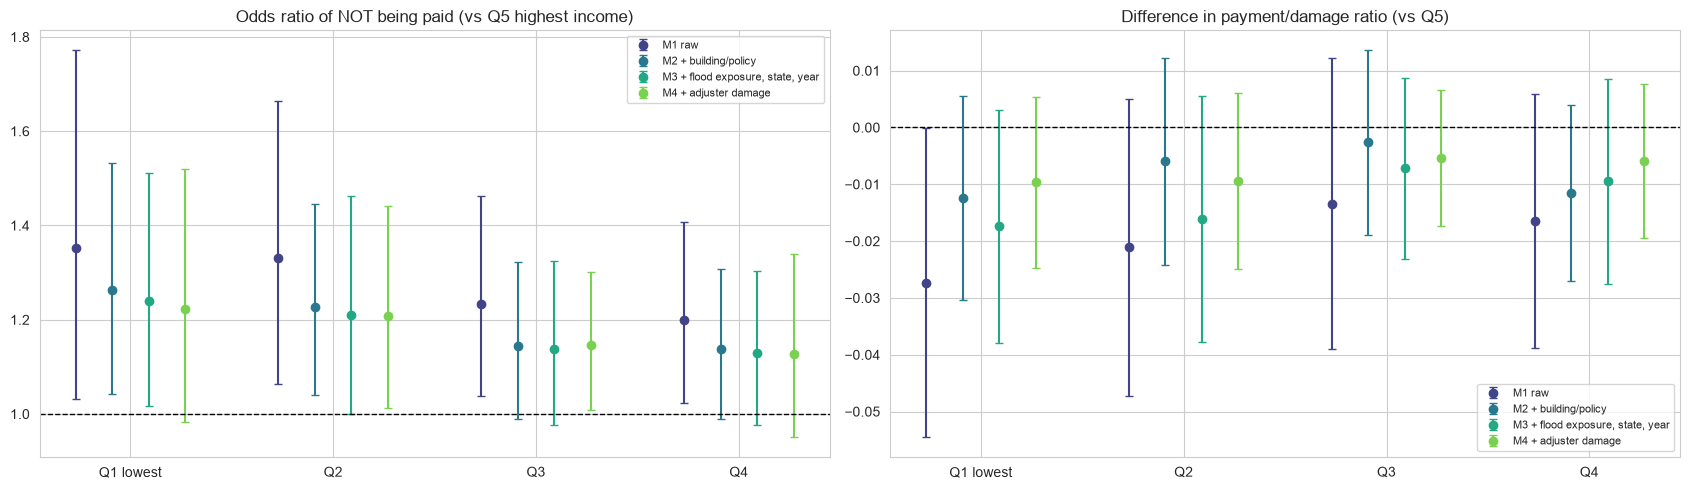

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
model_order = list(SPECIFICATIONS)
colors = sns.color_palette('viridis', len(model_order))
for ax, table, title, reference in [(axes[0], logit_table, 'Odds ratio of NOT being paid (vs Q5 highest income)', 1.0),
                                    (axes[1], ols_table, 'Difference in payment/damage ratio (vs Q5)', 0.0)]:
    for model_index, model_name in enumerate(model_order):
        subset = table[table['model'] == model_name].reset_index(drop=True)
        positions = np.arange(len(subset)) + (model_index - 1.5) * 0.18
        ax.errorbar(positions, subset['estimate'], yerr=[subset['estimate'] - subset['ci_low'], subset['ci_high'] - subset['estimate']],
                    fmt='o', color=colors[model_index], label=model_name, capsize=3)
    ax.axhline(reference, color='k', ls='--', lw=1)
    ax.set_xticks(range(4))
    ax.set_xticklabels(['Q1 lowest', 'Q2', 'Q3', 'Q4'])
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '08_rq6_effects_by_model.png', dpi=120)
plt.show()

---
# Section 5: The Same Question for Race (majority non-Hispanic White vs not)

In [8]:
race_rows = []
for specification in ['M1 raw', 'M3 + flood exposure, state, year', 'M4 + adjuster damage']:
    controls = SPECIFICATIONS[specification]
    formula = "not_paid ~ C(majority_white, Treatment('majority_NH_white'))" + (f' + {controls}' if controls else '')
    result = smf.logit(formula, data=model_data).fit(disp=False, maxiter=200, cov_type='cluster',
                                                     cov_kwds={'groups': pd.factorize(model_data['county_geoid'])[0]})
    term = "C(majority_white, Treatment('majority_NH_white'))[T.majority_non_white]"
    ols_result = smf.ols(formula.replace('not_paid', 'payment_to_damage_ratio'), data=damaged).fit(
        cov_type='cluster', cov_kwds={'groups': pd.factorize(damaged['county_geoid'])[0]})
    race_rows.append({'model': specification, 'odds_ratio_not_paid (non-White vs White)': np.exp(result.params[term]),
                      'OR_p_value': result.pvalues[term], 'payment_ratio_difference': ols_result.params[term],
                      'ratio_p_value': ols_result.pvalues[term]})
race_table = pd.DataFrame(race_rows).round(4)
race_table.to_csv(TABLE_DIR / '08_rq6_race_effects.csv', index=False)
print(race_table.to_string(index=False))

                           model  odds_ratio_not_paid (non-White vs White)  OR_p_value  payment_ratio_difference  ratio_p_value
                          M1 raw                                    1.4419      0.0025                   -0.0200         0.1593
M3 + flood exposure, state, year                                    1.2797      0.0325                   -0.0191         0.0615
            M4 + adjuster damage                                    1.2193      0.0090                   -0.0168         0.0048


---
# Section 6: Where Do the Raw Gaps Come From? (decomposition by blocks)

We look at how much of the Q1-vs-Q5 gap in non-payment is removed by each block of controls.

In [9]:
q1_or = logit_table[logit_table['quintile'] == 'Q1_lowest'].set_index('model')['estimate']
log_gap = np.log(q1_or)
decomposition = pd.DataFrame({'Q1_vs_Q5_odds_ratio': q1_or, 'log_odds_gap': log_gap,
                              'share_of_raw_gap_remaining_%': log_gap / log_gap.iloc[0] * 100 if log_gap.iloc[0] != 0 else np.nan})
print(decomposition.round(3).to_string())

                                  Q1_vs_Q5_odds_ratio  log_odds_gap  share_of_raw_gap_remaining_%
model                                                                                            
M1 raw                                          1.352         0.301                       100.000
M2 + building/policy                            1.264         0.234                        77.648
M3 + flood exposure, state, year                1.240         0.215                        71.292
M4 + adjuster damage                            1.222         0.200                        66.436


In [10]:
results_rq6 = {'raw_by_income': raw_by_income.round(4).reset_index().to_dict('records'),
               'nonpayment_odds_ratios': logit_table.round(4).to_dict('records'),
               'payment_ratio_effects': ols_table.round(4).to_dict('records'), 'race': race_table.to_dict('records'),
               'decomposition': decomposition.round(4).reset_index().to_dict('records')}
json.dump(results_rq6, open(TABLE_DIR / '08_rq6_results.json', 'w'), indent=2, default=str)

---
## The numbers behind the answer

Read back from the saved tables (`tables/08_*`). M3 is the main result; M4 is the sensitivity check.

In [11]:
odds_saved = pd.read_csv(TABLE_DIR / '08_rq6_nonpayment_odds_ratios.csv')
ratio_saved = pd.read_csv(TABLE_DIR / '08_rq6_payment_ratio_effects.csv')
race_saved = pd.read_csv(TABLE_DIR / '08_rq6_race_effects.csv').set_index('model')
raw_income_saved = pd.read_csv(TABLE_DIR / '08_rq6_raw_by_income.csv').set_index('income_quintile')
raw_race_saved = pd.read_csv(TABLE_DIR / '08_rq6_raw_by_race.csv', index_col=0)
rows = [('rows in the models', len(model_data), 'this notebook'),
        ('raw not-paid rate Q1 lowest vs Q5 highest', f"{raw_income_saved.loc['Q1_lowest', 'not_paid_rate']:.3f} vs {raw_income_saved.loc['Q5_highest', 'not_paid_rate']:.3f}", '08_rq6_raw_by_income')]
if 'not_paid_rate' in raw_race_saved.columns:
    rows.append(('raw not-paid rate by majority race', ', '.join(f'{i}: {v:.3f}' for i, v in raw_race_saved['not_paid_rate'].items()), '08_rq6_raw_by_race'))
for model_name in odds_saved['model'].unique():
    q1 = odds_saved[(odds_saved['model'] == model_name) & (odds_saved['quintile'] == 'Q1_lowest')].iloc[0]
    rows.append((f'Q1 vs Q5 odds ratio not paid, {model_name} [95% CI]', f"{q1['estimate']:.2f} [{q1['ci_low']:.2f}-{q1['ci_high']:.2f}], p = {q1['p_value']:.3f}", '08_rq6_nonpayment_odds_ratios'))
for model_name in ratio_saved['model'].unique():
    q1 = ratio_saved[(ratio_saved['model'] == model_name) & (ratio_saved['quintile'] == 'Q1_lowest')].iloc[0]
    rows.append((f'Q1 vs Q5 payment/damage difference, {model_name}', f"{q1['estimate']:+.4f} [{q1['ci_low']:+.4f}, {q1['ci_high']:+.4f}], p = {q1['p_value']:.3f}", '08_rq6_payment_ratio_effects'))
for model_name in race_saved.index:
    r = race_saved.loc[model_name]
    rows.append((f'non-White vs White, {model_name}: OR not paid (p); ratio diff (p)',
                 f"{r['odds_ratio_not_paid (non-White vs White)']:.2f} ({r['OR_p_value']:.3f}); {r['payment_ratio_difference']:+.4f} ({r['ratio_p_value']:.4f})", '08_rq6_race_effects'))
for model_name, share in decomposition['share_of_raw_gap_remaining_%'].items():
    rows.append((f'share of raw log-odds gap remaining, {model_name} %', share, 'this notebook (decomposition)'))
answer_numbers = show_answer_numbers(rows, '08_rq6')

                                                                             quantity                                               value                        source
                                                                   rows in the models                                              232820                 this notebook
                                            raw not-paid rate Q1 lowest vs Q5 highest                                      0.176 vs 0.147          08_rq6_raw_by_income
                                                   raw not-paid rate by majority race majority_NH_white: 0.157, majority_non_white: 0.210            08_rq6_raw_by_race
                                        Q1 vs Q5 odds ratio not paid, M1 raw [95% CI]                         1.35 [1.03-1.77], p = 0.029 08_rq6_nonpayment_odds_ratios
                          Q1 vs Q5 odds ratio not paid, M2 + building/policy [95% CI]                         1.26 [1.04-1.53], p = 0.017 08_rq6_nonpayment_odds

---
# Research Question -> Answer

> **RQ6. Do claims in lower-income (and majority non-White) neighbourhoods have higher non-payment rates and lower
> payment-to-damage ratios, and does the gap remain after controls?**

**Answer: a small gap in non-payment remains after the controls, but the evidence is weak, and it is about
neighbourhoods, not households.** (Numbers from the `answer_numbers` table above; 232,820 claims in the models.)

**M3 is the main result.** M3 controls for everything that existed *before* the adjuster arrived: building, policy,
flood exposure (rain, storm, coast), state and year. M4 adds the adjuster's damage estimate. That is a possible
**bad control** (a mediator): if claims in poorer areas were assessed differently, part of the gap would run *through*
the damage estimate, and controlling for it would hide that part. So M4 is only a sensitivity check.

| Lowest vs highest income quintile | Raw (M1) | + building/policy (M2) | **+ flood exposure, state, year (M3, main)** | + adjuster damage (M4, sensitivity) |
|---|---|---|---|---|
| Odds ratio of not being paid [95% CI] | 1.35 [1.03-1.77] | 1.26 [1.04-1.53] | **1.24 [1.02-1.51], p = 0.033** | 1.22 [0.98-1.52], p = 0.072 |
| Payment/damage ratio difference [95% CI] | -0.027 [-0.055, -0.000] | -0.012 [-0.030, +0.006] | **-0.017 [-0.038, +0.003], p = 0.10** | -0.010 [-0.025, +0.005] |
| Share of the raw log-odds gap remaining | 100% | 78% | **71%** | 66% |

- **Reproduction.** The raw comparison shows the kind of gap the published descriptive work reports: 17.6% vs
  14.7% not paid by income, and 21.0% vs 15.7% by race.
- **Extension: the gap is not explained by exposure.** My first expectation was that rain, storm and flood zone would
  explain most of the gap. They do not. In the main model (M3) about **71% of the raw log-odds gap remains**
  (OR 1.24, CI 1.02-1.51). Adding the adjuster's damage (M4) lowers it only a little (OR 1.22), but the interval
  now touches 1 (0.98-1.52). For race the odds ratio goes from 1.44 (raw) to 1.28 in M3 (p = 0.03) and 1.22 in M4.
- **The payment-to-damage gap is small.** In M3, claims in the lowest quintile are paid about 1.7 percentage points
  less per dollar of damage (p = 0.10, not significant at 5%). For race the M3 difference is about 1.9 points
  (p = 0.06); only in M4 does it reach p < 0.01 (1.7 points).
- **Weak evidence.** Standard errors are clustered by county, so the confidence intervals are wide. The lower bound
  is close to 1.
- **What it does not show.** The cause is unknown. Possible reasons are documentation and filing behaviour (for
  example, more claims filed that turn out below the deductible), contents/building mix, adjusting firms, or
  unmeasured building condition. ACS describes the block group (ecological inference). This result is a reason to
  look closer, not proof of unfair treatment.